In [1]:
import pandas as pd
import joblib
import numpy as np

In [2]:
frontier_df = pd.read_csv('25_all_rows_new_id.csv')

C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\3535377745.py:1: DtypeWarning: Columns (50) have mixed types. Specify dtype option on import or set low_memory=False.
  frontier_df = pd.read_csv('25_all_rows_new_id.csv')


In [3]:
xgb_z_model = joblib.load('simple_bat_speed_z_score_model.joblib')

In [4]:
frontier_df['play_result'].value_counts()

play_result
undefined          208137
out                 26678
single              10646
double               2783
home_run             1416
fielders_choice      1147
sacrifice            1026
error                 975
triple                239
stolen_base            84
caught_stealing        10
Name: count, dtype: int64

In [5]:
frontier_df['k_or_bb'].value_counts()

k_or_bb
undefined    233629
strikeout     12595
walk           6917
Name: count, dtype: int64

In [6]:
# 1. COLUMN MAPPING & CLEANING
# Dropping NaNs is critical here to avoid the XGBoostError during Z-transformation
frontier_df = frontier_df.rename(columns={
    'exit_speed': 'launch_speed', # Using raw; Z-score handles the shift
    'height_in': 'height_inches',
    'angle': 'launch_angle',
    'direction': 'spray_angle',
}).dropna(subset=['launch_speed', 'height_inches', 'launch_angle', 'spray_angle'])

# 2. FEATURE ENGINEERING
frontier_df['is_2_strikes'] = (frontier_df['strikes'] == 2).astype(int)

features = [
    'launch_speed',
    'height_inches',
    'launch_angle',
    'spray_angle',
    'is_2_strikes'
]

# 1. DROP DUPLICATE COLUMNS (Prevention)
# If 'launch_speed' already existed before your rename, this cleans it up
frontier_df = frontier_df.loc[:, ~frontier_df.columns.duplicated()].copy()

# 2. UPDATED Z-SCORE LOOP
z_features = []
for col in features:
    z_col = f'z_{col}'

    # Calculate stats
    mu = frontier_df[col].mean()
    sigma = frontier_df[col].std()

    # Handle the 'ambiguity' and the zero-variance case
    # If sigma is a Series (multi-col), we take the first value;
    # if it's 0 or NaN, we default to 1 to avoid division errors.
    actual_sigma = sigma.iloc[0] if hasattr(sigma, 'iloc') else sigma
    if pd.isna(actual_sigma) or actual_sigma == 0:
        actual_sigma = 1

    frontier_df[z_col] = (frontier_df[col] - mu) / actual_sigma
    z_features.append(z_col)

print(f"Standardized {len(z_features)} features into Z-space.")

# 4. GENERATE Z-PREDICTIONS
# we create a temporary dataframe with the Z-values but original names
X_input = frontier_df[z_features].copy()
X_input.columns = features # rename ['z_launch_speed', ...] -> ['launch_speed', ...]

# now the model will accept the data because the names match its 'memory'
frontier_df['pred_z_bat_speed'] = xgb_z_model.predict(X_input)





Standardized 5 features into Z-space.


In [7]:
frontier_df['pitch_call'].value_counts()

pitch_call
in_play               28413
foul_not_fieldable    18916
foul_fieldable          314
undefined               178
ball_called             135
strike_called           103
hit_by_pitch             71
strike_swinging          61
ball_in_dirt             10
foul_ball                 3
ball_intentional          2
Name: count, dtype: int64

In [8]:
# 1. define the weights
base_map = {
    'single': 1,
    'double': 2,
    'triple': 3,
    'home_run': 4,
    'out': 0,
    'fielders_choice': 0,
    'error': 0
}

# 2. create binary flags for hits and at-bats
# we only care about rows where a plate appearance ended
frontier_df['bases'] = frontier_df['play_result'].map(base_map).fillna(0)

frontier_df['is_hit'] = frontier_df['play_result'].isin(['single', 'double', 'triple', 'home_run']).astype(int)

# ab = hit + out + fielders_choice + error + strikeout
frontier_df['is_ab'] = (
    frontier_df['play_result'].isin(['single', 'double', 'triple', 'home_run', 'out', 'fielders_choice', 'error']) |
    (frontier_df['k_or_bb'] == 'strikeout')
).astype(int)

# 3. aggregate to player level
# we sum the bases/hits/abs across the season, but take the top 90% mean of the predictions
def a_swing_mean(x):
    clean = x.dropna()
    if len(clean) < 5: return np.nan
    return clean[clean >= clean.quantile(0.10)].mean()

frontier_talent = frontier_df.groupby('batter').agg({
    'bases': 'sum',
    'is_hit': 'sum',
    'is_ab': 'sum',
    'pred_z_bat_speed': a_swing_mean
}).dropna()

# 4. compute final metrics
# filter for at least 50 abs to remove small-sample noise
frontier_talent = frontier_talent[frontier_talent['is_ab'] >= 50].copy()

frontier_talent['avg'] = frontier_talent['is_hit'] / frontier_talent['is_ab']
frontier_talent['slg'] = frontier_talent['bases'] / frontier_talent['is_ab']
frontier_talent['iso'] = frontier_talent['slg'] - frontier_talent['avg']

# 5. the ultimate test: correlation
print("--- frontier league: raw prediction vs power outcomes ---")
print(frontier_talent[['pred_z_bat_speed', 'iso', 'slg', 'avg']].corr()['pred_z_bat_speed'])

--- frontier league: raw prediction vs power outcomes ---
pred_z_bat_speed    1.000000
iso                 0.588491
slg                 0.576438
avg                 0.353821
Name: pred_z_bat_speed, dtype: float64


In [9]:
frontier_df['launch_speed'].describe()

count    48206.000000
mean        79.714157
std         15.192611
min          3.711570
25%         69.723020
50%         79.693880
75%         91.801137
max        128.307430
Name: launch_speed, dtype: float64

In [10]:
def cronbach_alpha(item_scores):
    """
    Rows = subjects (players), columns = items (random splits of their swings).
    Returns the reliability of the sum/mean across all k items.
    """
    item_scores = item_scores.dropna()
    k = item_scores.shape[1]
    item_var = item_scores.var(axis=0, ddof=1).sum()
    total_var = item_scores.sum(axis=1).var(ddof=1)
    return (k / (k - 1)) * (1 - item_var / total_var)


# --- 1. setup ---
n_splits = 4                     # number of random buckets per player
min_swings_per_split = 25 # ensures a_swing_mean's >=5 floor + room after the 10% trim

valid = frontier_df.dropna(subset=['pred_z_bat_speed']).copy()

# only keep players with enough swings to fill every bucket
counts = valid.groupby('batter').size()
keep = counts[counts >= min_swings_per_split * n_splits].index
valid = valid[valid['batter'].isin(keep)].copy()

# --- 2. randomly assign each swing to a bucket, within player ---
rng = np.random.default_rng(42)
valid['split'] = valid.groupby('batter')['pred_z_bat_speed'].transform(
    lambda x: rng.integers(0, n_splits, size=len(x))
)

# --- 3. aggregate with your a_swing_mean inside each (batter, split) cell ---
split_means = (
    valid.groupby(['batter', 'split'])['pred_z_bat_speed']
         .apply(a_swing_mean)
         .unstack('split')
)

# --- 4. compute Cronbach's Alpha ---
alpha = cronbach_alpha(split_means)
n_players = len(split_means.dropna())

print(f"--- Cronbach's Alpha on a_swing_mean(pred_z_bat_speed) ---")
print(f"k splits           : {n_splits}")
print(f"players included   : {n_players}")
print(f"alpha              : {alpha:.4f}")

# optional: per-bucket reliability (i.e. reliability of a single split)
# useful if you want to know how reliable one bucket alone is
single_split_rel = alpha / (n_splits - (n_splits - 1) * alpha)
print(f"single-split est.  : {single_split_rel:.4f}")

--- Cronbach's Alpha on a_swing_mean(pred_z_bat_speed) ---
k splits           : 4
players included   : 153
alpha              : 0.9803
single-split est.  : 0.9255


In [11]:
# =========================================================
# Part 1: Reliability as a function of N swings
# =========================================================
# Strategy: for each target N, sample N swings per player, randomly
# split into 2 halves of N/2, compute a_swing_mean on each half,
# correlate, apply Spearman-Brown to get reliability of full N.
# Average over iterations to reduce splitting noise.

def reliability_at_n(df, col, n, n_iters=25, seed=42):
    rng = np.random.default_rng(seed)
    valid = df.dropna(subset=[col])
    counts = valid.groupby('batter').size()
    keep = counts[counts >= n].index
    sub = valid[valid['batter'].isin(keep)]

    if len(keep) < 20:
        return {'n_swings': n, 'n_players': len(keep),
                'reliability': np.nan, 'r_halfhalf': np.nan, 'sd': np.nan}

    sb_vals = []
    for _ in range(n_iters):
        # sample exactly n swings per player
        sampled = (sub.groupby('batter', group_keys=False)
                      .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
        sampled = sampled.assign(half=rng.integers(0, 2, size=len(sampled)))
        halves = (sampled.groupby(['batter', 'half'])[col]
                          .apply(a_swing_mean)
                          .unstack('half')
                          .dropna())
        if len(halves) < 10:
            continue
        r = halves[0].corr(halves[1])
        sb_vals.append(2 * r / (1 + r) if r > -1 else np.nan)

    return {'n_swings': n, 'n_players': len(keep),
            'reliability': np.mean(sb_vals),
            'r_halfhalf': np.mean(sb_vals) / (2 - np.mean(sb_vals)),  # back out half-half r
            'sd': np.std(sb_vals)}


n_grid = [5, 10, 15, 20, 30, 50, 75, 100]
curve = pd.DataFrame([reliability_at_n(frontier_df, 'pred_z_bat_speed', n)
                      for n in n_grid])
print("--- Reliability curve: a_swing_mean(pred_z_bat_speed) ---")
print(curve.to_string(index=False))

# Stabilization point: smallest N where reliability >= 0.70
stable = curve[curve['reliability'] >= 0.70]
if len(stable):
    print(f"\nStabilizes (>=0.70) at N ≈ {stable['n_swings'].iloc[0]} swings")


# =========================================================
# Part 2: H1 bat speed → H2 outcomes (AVG, SLG, ISO, xDamage)
# =========================================================
# Split each player's season chronologically at their personal median.
# Predictor: a_swing_mean of pred_z_bat_speed in H1.
# Targets: AVG, SLG, ISO, mean xDamage in H2.

# adjust these column names if yours differ
DATE_COL = 'date'     # or 'game_pk', or anything monotonic in time
XDAMAGE_COL = 'xdamage'     # or whatever your expected-damage column is named

df = frontier_df.sort_values(['batter', DATE_COL]).copy()

# assign half by within-player swing rank (gives equal n per half)
df['swing_rank'] = df.groupby('batter').cumcount()
df['n_swings_player'] = df.groupby('batter')['swing_rank'].transform('count')
df['half'] = np.where(df['swing_rank'] < df['n_swings_player'] / 2, 'H1', 'H2')

# H1: bat speed talent (predictor)
h1 = (df[df['half'] == 'H1']
      .groupby('batter')
      .agg(h1_bat_speed=('pred_z_bat_speed', a_swing_mean),
           h1_swings=('pred_z_bat_speed', lambda x: x.dropna().shape[0])))

# H2: outcomes (targets) — use the same bases/is_hit/is_ab columns from earlier
h2 = (df[df['half'] == 'H2']
      .groupby('batter')
      .agg(h2_bases=('bases', 'sum'),
           h2_hits=('is_hit', 'sum'),
           h2_abs=('is_ab', 'sum'),
           h2_xdamage=(XDAMAGE_COL, 'mean')))

split = h1.join(h2, how='inner').dropna()
split = split[(split['h1_swings'] >= 50) & (split['h2_abs'] >= 50)].copy()
split['h2_avg'] = split['h2_hits'] / split['h2_abs']
split['h2_slg'] = split['h2_bases'] / split['h2_abs']
split['h2_iso'] = split['h2_slg'] - split['h2_avg']

print(f"\n--- H1 → H2 predictive validity (n = {len(split)} players) ---")
out_cols = ['h2_avg', 'h2_slg', 'h2_iso', 'h2_xdamage']
print(split[['h1_bat_speed'] + out_cols].corr()['h1_bat_speed'].drop('h1_bat_speed'))

# also show the in-sample (whole-season) version for comparison
print(f"\n--- (Compare) Whole-season correlation, no train/test split ---")
print(frontier_talent[['pred_z_bat_speed', 'avg', 'slg', 'iso']]
      .corr()['pred_z_bat_speed'].drop('pred_z_bat_speed'))

C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\3544169706.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\3544169706.py:24: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\3544169706.py:24

--- Reliability curve: a_swing_mean(pred_z_bat_speed) ---
 n_swings  n_players  reliability  r_halfhalf       sd
        5        182          NaN         NaN      NaN
       10        181     0.622890    0.452317 0.101263
       15        179     0.709061    0.549259 0.052673
       20        177     0.774138    0.631506 0.026041
       30        174     0.840354    0.724664 0.017824
       50        169     0.901973    0.821449 0.010202
       75        161     0.933893    0.875985 0.005788
      100        153     0.951778    0.907993 0.006406

Stabilizes (>=0.70) at N ≈ 15 swings

--- H1 → H2 predictive validity (n = 122 players) ---
h2_avg        0.246051
h2_slg        0.461415
h2_iso        0.476495
h2_xdamage    0.527231
Name: h1_bat_speed, dtype: float64

--- (Compare) Whole-season correlation, no train/test split ---
avg    0.353821
slg    0.576438
iso    0.588491
Name: pred_z_bat_speed, dtype: float64


In [12]:
def trimmed_mean(top_pct):
    """Returns a function that averages the top `top_pct` fraction of values."""
    cutoff = 1 - top_pct  # e.g. top 90% -> drop bottom 10% -> cutoff at 0.10
    def fn(x):
        clean = x.dropna()
        if len(clean) < 5: return np.nan
        return clean[clean >= clean.quantile(cutoff)].mean()
    return fn


def reliability_at_n(df, col, n, agg_fn, n_iters=25, seed=42):
    rng = np.random.default_rng(seed)
    valid = df.dropna(subset=[col])
    counts = valid.groupby('batter').size()
    keep = counts[counts >= n].index
    sub = valid[valid['batter'].isin(keep)]
    if len(keep) < 20:
        return np.nan

    sb_vals = []
    for _ in range(n_iters):
        sampled = (sub.groupby('batter', group_keys=False)
                      .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
        sampled = sampled.assign(half=rng.integers(0, 2, size=len(sampled)))
        halves = (sampled.groupby(['batter', 'half'])[col]
                          .apply(agg_fn)
                          .unstack('half')
                          .dropna())
        if len(halves) < 10:
            continue
        r = halves[0].corr(halves[1])
        if r > -1:
            sb_vals.append(2 * r / (1 + r))
    return np.mean(sb_vals) if sb_vals else np.nan


variants = {
    'plain_mean':  lambda x: x.dropna().mean() if x.dropna().shape[0] >= 5 else np.nan,
    'top_90pct':   trimmed_mean(0.90),   # drop bottom 10% (your current a_swing_mean)
    'top_75pct':   trimmed_mean(0.75),
    'top_50pct':   trimmed_mean(0.50),
    'top_10pct':   trimmed_mean(0.10),   # "peak" — only the hardest swings
}

n_grid = [10, 15, 20, 30, 50, 75, 100]
results = pd.DataFrame(
    {name: [reliability_at_n(frontier_df, 'pred_z_bat_speed', n, fn)
            for n in n_grid]
     for name, fn in variants.items()},
    index=n_grid
)
results.index.name = 'n_swings'
print("--- Reliability by aggregation method ---")
print(results.round(4))

C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\3462029394.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\3462029394.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\3462029394.py:23

KeyboardInterrupt: 

In [13]:
# =========================================================
# Unified comparison across trim variants
# =========================================================

variants = {
    'plain_mean':  lambda x: x.dropna().mean() if x.dropna().shape[0] >= 5 else np.nan,
    'top_90pct':   trimmed_mean(0.90),
    'top_75pct':   trimmed_mean(0.75),
    'top_50pct':   trimmed_mean(0.50),
    'top_25pct':   trimmed_mean(0.25),
    'top_10pct':   trimmed_mean(0.10),
}

DATE_COL = 'date'
XDAMAGE_COL = 'xdamage'   # adjust if needed

# ---------- Build H1/H2 split once (shared across variants) ----------
df = frontier_df.sort_values(['batter', DATE_COL]).copy()
df['swing_rank'] = df.groupby('batter').cumcount()
df['n_swings_player'] = df.groupby('batter')['swing_rank'].transform('count')
df['half'] = np.where(df['swing_rank'] < df['n_swings_player'] / 2, 'H1', 'H2')

# H2 outcomes (same for every variant — only the H1 predictor changes)
h2 = (df[df['half'] == 'H2']
      .groupby('batter')
      .agg(h2_bases=('bases', 'sum'),
           h2_hits=('is_hit', 'sum'),
           h2_abs=('is_ab', 'sum'),
           h2_xdamage=(XDAMAGE_COL, 'mean')))
h2 = h2[h2['h2_abs'] >= 50].copy()
h2['h2_avg'] = h2['h2_hits'] / h2['h2_abs']
h2['h2_slg'] = h2['h2_bases'] / h2['h2_abs']
h2['h2_iso'] = h2['h2_slg'] - h2['h2_avg']

# Whole-season outcomes (for in-sample correlation)
whole = (frontier_df.groupby('batter')
         .agg(bases=('bases', 'sum'),
              is_hit=('is_hit', 'sum'),
              is_ab=('is_ab', 'sum'),
              xdamage=(XDAMAGE_COL, 'mean')))
whole = whole[whole['is_ab'] >= 50].copy()
whole['avg'] = whole['is_hit'] / whole['is_ab']
whole['slg'] = whole['bases'] / whole['is_ab']
whole['iso'] = whole['slg'] - whole['avg']


# ---------- Loop over variants ----------
rows = []
for name, fn in variants.items():
    # whole-season talent (in-sample predictor)
    talent = (frontier_df.groupby('batter')['pred_z_bat_speed']
              .apply(fn).rename('talent').to_frame())
    in_sample = talent.join(whole, how='inner').dropna()

    # H1 talent (out-of-sample predictor)
    h1_talent = (df[df['half'] == 'H1']
                 .groupby('batter')['pred_z_bat_speed']
                 .apply(fn).rename('h1_talent').to_frame())
    out_sample = h1_talent.join(h2, how='inner').dropna()

    # reliability at N=50 as a single summary number
    rel_50 = reliability_at_n(frontier_df, 'pred_z_bat_speed', 50, fn)

    rows.append({
        'variant': name,
        'reliability@50': rel_50,
        # in-sample (whole season vs whole season)
        'in_avg':  in_sample[['talent', 'avg']].corr().iloc[0, 1],
        'in_slg':  in_sample[['talent', 'slg']].corr().iloc[0, 1],
        'in_iso':  in_sample[['talent', 'iso']].corr().iloc[0, 1],
        'in_xdmg': in_sample[['talent', 'xdamage']].corr().iloc[0, 1],
        # out-of-sample (H1 predictor → H2 outcomes)
        'h2_avg':  out_sample[['h1_talent', 'h2_avg']].corr().iloc[0, 1],
        'h2_slg':  out_sample[['h1_talent', 'h2_slg']].corr().iloc[0, 1],
        'h2_iso':  out_sample[['h1_talent', 'h2_iso']].corr().iloc[0, 1],
        'h2_xdmg': out_sample[['h1_talent', 'h2_xdamage']].corr().iloc[0, 1],
        'n_in':    len(in_sample),
        'n_out':   len(out_sample),
    })

results = pd.DataFrame(rows).set_index('variant')
print("--- Reliability + correlation + predictive validity by trim ---")
print(results.round(4).to_string())

# Bonus: shrinkage from in-sample to out-of-sample (how much was inflated)
print("\n--- Shrinkage: out-of-sample / in-sample ratio (closer to 1.0 = more honest signal) ---")
shrinkage = pd.DataFrame({
    'avg':  results['h2_avg']  / results['in_avg'],
    'slg':  results['h2_slg']  / results['in_slg'],
    'iso':  results['h2_iso']  / results['in_iso'],
    'xdmg': results['h2_xdmg'] / results['in_xdmg'],
}, index=results.index)
print(shrinkage.round(3).to_string())

C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\3462029394.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\3462029394.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n, random_state=rng.integers(1e9))))
C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\3462029394.py:23

KeyboardInterrupt: 

In [34]:
"""
batspeed_plus_2025_2026.py
--------------------------
Pull all 2025 + 2026 swings from Supabase, run the bat speed model,
aggregate per (batter, year) with a_swing_mean (top 90%), scale to a
fixed 2025 FL baseline so both years are on the same yardstick, and
write out a leaderboard + per-player report data.

A player who appears in both years gets two rows — one per season —
so you can see year-over-year movement directly.
"""

import os
import sys
import joblib
import numpy as np
import pandas as pd
from sqlalchemy import create_engine, text

# ----------------------------------------------------------------------
# CONFIG  -- EDIT THESE
# ----------------------------------------------------------------------

SUPABASE = {
    'host':     'aws-1-us-east-1.pooler.supabase.com',
    'port':     6542,
    'database': 'postgres',
    'user':     'postgres.zqspccujqmbzsxulnrqt',
    'password': 'REMOVED-see-secrets.toml',
}

# Bat speed model + feature list
BAT_SPEED_MODEL_PATH = r'C:\Users\215nt\PycharmProjects\FLStuff\FLHitting\simple_bat_speed_z_score_model.joblib'
# Map: model feature name  ->  raw DB column name
FEATURE_DB_MAP = {
    'launch_speed':  'exit_speed',
    'launch_angle':  'angle',
    'spray_angle':   'direction',
    'height_inches': 'height_in',
    # 'is_2_strikes' is derived from `strikes`, handled separately
}

BAT_SPEED_FEATURES = [
    'launch_speed',
    'height_inches',     # <- moved up
    'launch_angle',
    'spray_angle',
    'is_2_strikes',
]

# Source table
TABLE         = 'pitches'
DATE_COL      = 'date'
BATTER_COL  = 'batter_id'
BATTER_NAME = 'batter'

# Pull window — all of 2025 + all of 2026
PULL_START = '2025-01-01'
PULL_END   = '2026-12-31'

# Baseline constants — 2025 FL regular season pred_z_bat_speed distribution.
# Compute once, hardcode here. Both 2025 and 2026 leaderboards scale to this
# so the numbers are directly comparable across years.


def a_swing_mean(x):
    clean = x.dropna()
    if len(clean) < 5:
        return np.nan
    return clean[clean >= clean.quantile(0.10)].mean()

MIN_SWINGS_BY_YEAR = {
    2025: 50,
    2026: 16,
}
min_swings = 1
QUALIFIED_THRESHOLDS = {
    2025: 50,   # same as min — all 2025 rows on the board are qualified
    2026: 16,   # 12-15 swing batters appear but flagged as preliminary
}
OUTPUT_DIR = r'C:\Users\215nt\PycharmProjects\FLStuff\reports\batspeed_plus'


# ----------------------------------------------------------------------
# 1.  PULL  ------------------------------------------------------------
# ----------------------------------------------------------------------

def get_engine():
    cfg = SUPABASE
    url = (f"postgresql+psycopg2://{cfg['user']}:{cfg['password']}"
           f"@{cfg['host']}:{cfg['port']}/{cfg['database']}")
    return create_engine(
        url, pool_pre_ping=True, pool_size=2, max_overflow=3, pool_recycle=300,
        connect_args={'sslmode': 'require'},
    )


def pull_swings() -> pd.DataFrame:
    """Pull balls-in-play across 2025 + 2026 (bat speed model is BBE-only)."""
    db_feature_cols = list(FEATURE_DB_MAP.values())
    cols = ', '.join(dict.fromkeys(db_feature_cols + [
        'strikes',                                                # for is_2_strikes
        BATTER_COL, BATTER_NAME, DATE_COL,
        'pitch_call', 'play_result', 'k_or_bb', 'batter_team'
    ]))
    q = text(f"""
        SELECT {cols}
        FROM {TABLE}
        WHERE {DATE_COL}::timestamp >= :start
          AND {DATE_COL}::timestamp <= :end
          AND exit_speed IS NOT NULL
    """)
    with get_engine().connect() as conn:
        df = pd.read_sql(q, conn, params={'start': PULL_START, 'end': PULL_END})

    df.columns = [c.lower().strip() for c in df.columns]

    # Match local pipeline: rename DB cols -> model feature names
    df = df.rename(columns={v: k for k, v in FEATURE_DB_MAP.items()})
    df['is_2_strikes'] = (df['strikes'] == 2).astype(int)
    df['year'] = pd.to_datetime(df[DATE_COL]).dt.year
    return df


# ----------------------------------------------------------------------
# 2.  PREDICT  ---------------------------------------------------------
# ----------------------------------------------------------------------

def add_bat_speed_predictions(df: pd.DataFrame) -> pd.DataFrame:
    model = joblib.load(BAT_SPEED_MODEL_PATH)
    feats = BAT_SPEED_FEATURES

    df = df.dropna(subset=feats).copy()

    # Z-score using stats from the pulled FL data itself
    X = pd.DataFrame(index=df.index)
    for col in feats:
        X[col] = (df[col] - df[col].mean()) / df[col].std()

    df['pred_z_bat_speed'] = model.predict(X)
    return df


# ----------------------------------------------------------------------
# 3.  AGGREGATE + SCALE  -----------------------------------------------
# ----------------------------------------------------------------------

def build_leaderboard(df: pd.DataFrame, mu: float, sigma: float) -> pd.DataFrame:
    grouped = df.groupby([BATTER_COL, BATTER_NAME, 'year', 'batter_team']).agg(
        swings=('pred_z_bat_speed', lambda x: x.dropna().shape[0]),
        avg_pred_z=('pred_z_bat_speed', a_swing_mean),
    ).reset_index()

    # Inclusion threshold (appears on the board)
    min_swings_for_row = grouped['year'].map(MIN_SWINGS_BY_YEAR).fillna(25).astype(int)
    grouped = grouped[grouped['swings'] >= min_swings_for_row].copy()
    grouped['min_swings_threshold'] = grouped['year'].map(MIN_SWINGS_BY_YEAR)

    # Qualified threshold (reliable enough to take seriously)
    qual_threshold = grouped['year'].map(QUALIFIED_THRESHOLDS).fillna(25).astype(int)
    grouped['qualified'] = grouped['swings'] >= qual_threshold

    grouped['bat_speed_plus'] = (
        (grouped['avg_pred_z'] - mu) / (sigma + 1e-9) * 25 + 100
    ).round(1)

    grouped['year_pctile'] = (
        grouped.groupby('year')['avg_pred_z'].rank(pct=True) * 100
    ).round(0).astype('Int64')


    return grouped.sort_values(['year', 'qualified', 'bat_speed_plus'],
                               ascending=[True, False, False]).reset_index(drop=True)


def build_yoy_view(leaderboard: pd.DataFrame) -> pd.DataFrame:
    wide = leaderboard.pivot_table(
        index=[BATTER_COL, BATTER_NAME],
        columns='year',
        values=['bat_speed_plus', 'swings', 'year_pctile'],
    )
    wide.columns = [f'{a}_{b}' for a, b in wide.columns]
    wide = wide.reset_index()

    # Attach team — prefer most recent year on record
    team_lookup = (leaderboard.sort_values('year')
                              .groupby(BATTER_COL)['batter_team']
                              .last().reset_index())
    wide = wide.merge(team_lookup, on=BATTER_COL, how='left')

    if 'bat_speed_plus_2025' in wide and 'bat_speed_plus_2026' in wide:
        wide['delta'] = (wide['bat_speed_plus_2026']
                         - wide['bat_speed_plus_2025']).round(1)
        both = wide.dropna(subset=['bat_speed_plus_2025', 'bat_speed_plus_2026'])
        return both.sort_values('delta', ascending=False).reset_index(drop=True)
    return wide


# ----------------------------------------------------------------------
# 4.  PER-PLAYER REPORT DATA  ------------------------------------------
# ----------------------------------------------------------------------

def per_player_breakdown(df: pd.DataFrame, leaderboard: pd.DataFrame) -> list[dict]:
    """One record per (batter, year) — keyed for downstream report rendering."""
    qualified_keys = set(zip(leaderboard[BATTER_COL], leaderboard['year']))
    reports = []

    for (bid, yr), sub in df.groupby([BATTER_COL, 'year']):
        if (bid, yr) not in qualified_keys:
            continue
        row = leaderboard[(leaderboard[BATTER_COL] == bid)
                          & (leaderboard['year'] == yr)].iloc[0]

        rec = {
            'batter_id':       bid,
            'batter_name':     row[BATTER_NAME],
            'batter_team':     row['batter_team'],
            'year':            int(yr),
            'bat_speed_plus':  row['bat_speed_plus'],
            'year_pctile':     row['year_pctile'],
            'swings':          int(row['swings']),
            'mean_pred_z':     float(row['avg_pred_z']),
            'all_swings':      sub['pred_z_bat_speed'].dropna().tolist(),
        }

        if 'pitcher_throws' in sub.columns:
            rec['vs_lhp'] = a_swing_mean(sub.loc[sub['pitcher_throws'] == 'L', 'pred_z_bat_speed'])
            rec['vs_rhp'] = a_swing_mean(sub.loc[sub['pitcher_throws'] == 'R', 'pred_z_bat_speed'])
        if 'pitch_type' in sub.columns:
            rec['by_pitch'] = (sub.groupby('pitch_type')['pred_z_bat_speed']
                                  .apply(a_swing_mean).dropna().to_dict())

        reports.append(rec)
    return reports


# ----------------------------------------------------------------------
# 5.  RUN  -------------------------------------------------------------
# ----------------------------------------------------------------------

def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    print('[1/5] Pulling 2025 + 2026 swings…')
    df = pull_swings()
    by_year = df.groupby('year').size()
    print(f'      total pitches: {len(df):,}')
    for yr, n in by_year.items():
        print(f'        {yr}: {n:,} pitches  |  '
              f'{df.loc[df["year"] == yr, BATTER_COL].nunique()} batters')

    print('[2/5] Generating bat speed predictions…')
    df = add_bat_speed_predictions(df)

    # Compute FL baseline from pooled 2025+2026 predictions
    mu_fl    = df['pred_z_bat_speed'].mean()
    sigma_fl = df['pred_z_bat_speed'].std()
    print(f'      FL baseline (2025+2026 pooled): mu={mu_fl:.4f}, sigma={sigma_fl:.4f}')

    print('[3/5] Building leaderboard (per batter, per year)…')
    lb = build_leaderboard(df, mu_fl, sigma_fl)
    lb_path = os.path.join(OUTPUT_DIR, 'batspeed_plus_leaderboard.csv')
    lb.to_csv(lb_path, index=False)
    for yr in sorted(lb['year'].unique()):
        n_q = (lb['year'] == yr).sum()
        print(f'      {yr}: {n_q} batters on board '
              f'(>= {MIN_SWINGS_BY_YEAR.get(int(yr), 25)} swings)')
    print(f'      wrote {lb_path}')

    # Mississippi Mud Monsters 2026 leaderboard
    mud = lb[(lb['year'] == 2026)
             & (lb['batter_team'] == 'Mississippi Mud Monsters')].copy()
    mud_path = os.path.join(OUTPUT_DIR, 'batspeed_plus_mud_monsters_2026.csv')
    mud.to_csv(mud_path, index=False)
    print(f'      Mud Monsters 2026: {len(mud)} batters  |  wrote {mud_path}')

    print('[4/5] Building YoY comparison view…')
    yoy = build_yoy_view(lb)
    yoy_path = os.path.join(OUTPUT_DIR, 'batspeed_plus_yoy.csv')
    yoy.to_csv(yoy_path, index=False)
    print(f'      {len(yoy)} returning players  |  wrote {yoy_path}')

    print('[5/5] Building per-player breakdowns…')
    reports = per_player_breakdown(df, lb)
    rep_path = os.path.join(OUTPUT_DIR, 'batspeed_plus_player_reports.parquet')
    pd.DataFrame.from_records(reports).to_parquet(rep_path)
    print(f'      {len(reports)} player-year records  |  wrote {rep_path}')

    print('\nTop 15 by Bat Speed+ (2026):')
    print(lb[lb['year'] == 2026].head(15).to_string(index=False))
    print('\nTop 10 YoY gainers (2025 → 2026):')
    print(yoy.head(10).to_string(index=False))


if __name__ == '__main__':
    main()

[1/5] Pulling 2025 + 2026 swings…
      total pitches: 76,828
        2025: 73,074 pitches  |  383 batters
        2026: 3,754 pitches  |  221 batters
[2/5] Generating bat speed predictions…
      FL baseline (2025+2026 pooled): mu=-0.0473, sigma=0.6067
[3/5] Building leaderboard (per batter, per year)…
      2025: 176 batters on board (>= 50 swings)
      2026: 55 batters on board (>= 16 swings)
      wrote C:\Users\215nt\PycharmProjects\FLStuff\reports\batspeed_plus\batspeed_plus_leaderboard.csv
      Mud Monsters 2026: 6 batters  |  wrote C:\Users\215nt\PycharmProjects\FLStuff\reports\batspeed_plus\batspeed_plus_mud_monsters_2026.csv
[4/5] Building YoY comparison view…
      50 returning players  |  wrote C:\Users\215nt\PycharmProjects\FLStuff\reports\batspeed_plus\batspeed_plus_yoy.csv
[5/5] Building per-player breakdowns…
      226 player-year records  |  wrote C:\Users\215nt\PycharmProjects\FLStuff\reports\batspeed_plus\batspeed_plus_player_reports.parquet

Top 15 by Bat Speed+ (

In [24]:
# 1. Does the name match exactly?
matches = df[df[BATTER_NAME].str.contains('Booker', case=False, na=False)][BATTER_NAME].unique()
print('Name matches:', matches)

# 2. How many rows does he have, by year?
print('\nRow counts by year:')
print(df[df[BATTER_NAME].isin(matches)].groupby('year').size())

# 3. Are predictions NaN league-wide, or just for him?
print(f'\nLeague pred NaN rate: {df["pred_z_bat_speed"].isna().mean():.2%}')
print(f'2026 pred NaN rate:   {df.loc[df["year"]==2026, "pred_z_bat_speed"].isna().mean():.2%}')

# 4. If he has rows but all preds are NaN, check his raw features
booker = df[df[BATTER_NAME].isin(matches) & (df['year'] == 2026)]
print(f'\nBooker 2026 rows: {len(booker)}')
print(booker[BAT_SPEED_FEATURES + ['pred_z_bat_speed']].describe())

Name matches: ['Booker, Kyle']

Row counts by year:
year
2025.0    406
dtype: int64

League pred NaN rate: 0.00%
2026 pred NaN rate:   nan%

Booker 2026 rows: 0
       launch_speed  height_inches  launch_angle  spray_angle  is_2_strikes  \
count           0.0            0.0           0.0          0.0           0.0   
mean            NaN            NaN           NaN          NaN           NaN   
std             NaN            NaN           NaN          NaN           NaN   
min             NaN            NaN           NaN          NaN           NaN   
25%             NaN            NaN           NaN          NaN           NaN   
50%             NaN            NaN           NaN          NaN           NaN   
75%             NaN            NaN           NaN          NaN           NaN   
max             NaN            NaN           NaN          NaN           NaN   

       pred_z_bat_speed  
count               0.0  
mean                NaN  
std                 NaN  
min                 NaN

In [25]:
with get_engine().connect() as conn:
    booker_raw = pd.read_sql(text("""
        SELECT date, pitch_call, play_result, exit_speed, angle, direction
        FROM pitches
        WHERE batter = 'Booker, Kyle'
          AND date::timestamp >= '2026-01-01'
        ORDER BY date
    """), conn)

print(f'Total 2026 pitches in DB for Booker: {len(booker_raw)}')
print(f'  with exit_speed populated:        {booker_raw["exit_speed"].notna().sum()}')
print(f'  pitch_call breakdown:')
print(booker_raw['pitch_call'].value_counts())
print(f'\nFirst 10 rows:')
print(booker_raw.head(10).to_string())

Total 2026 pitches in DB for Booker: 167
  with exit_speed populated:        48
  pitch_call breakdown:
pitch_call
ball_called           63
foul_not_fieldable    30
strike_called         26
in_play               25
strike_swinging       22
hit_by_pitch           1
Name: count, dtype: int64

First 10 rows:
         date          pitch_call play_result  exit_speed      angle   direction
0  2026-04-23     strike_swinging   undefined         NaN        NaN         NaN
1  2026-04-23       strike_called   undefined         NaN        NaN         NaN
2  2026-04-23         ball_called   undefined         NaN        NaN         NaN
3  2026-04-23     strike_swinging   undefined         NaN        NaN         NaN
4  2026-04-23       strike_called   undefined         NaN        NaN         NaN
5  2026-04-23         ball_called   undefined         NaN        NaN         NaN
6  2026-04-23         ball_called   undefined         NaN        NaN         NaN
7  2026-04-23         ball_called   undefined

Booker 2026 swings with predictions: 48
      date         pitch_call  launch_speed  launch_angle  spray_angle  pred_z_bat_speed
2026-05-07            in_play     108.50970     15.458446    25.335500          1.083900
2026-05-07            in_play      67.40271    -49.142770    70.624188         -0.428888
2026-05-03 foul_not_fieldable      78.81727     50.230368   -87.786169          0.086307
2026-05-03    strike_swinging      71.34040     64.203666  -121.372059          0.106419
2026-05-03            in_play      90.78157    -12.295951    34.810801         -0.046425
2026-05-08            in_play      85.63109     14.628763   -26.498325         -0.091241
2026-05-08 foul_not_fieldable      63.22202     23.182978  -160.196342         -0.867725
2026-05-08 foul_not_fieldable      72.64369     56.751087  -170.280114         -0.317237
2026-05-08            in_play      84.29517     -7.773509    -7.233741         -0.477280
2026-05-08 foul_not_fieldable      73.57608     16.801001  -170.267467

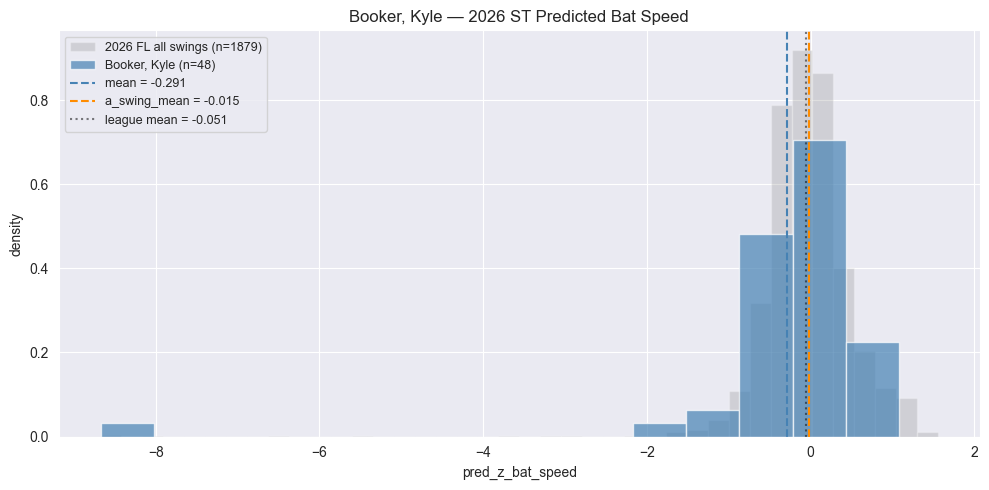


Summary:
  swings:        48
  mean:          -0.291
  a_swing_mean:  -0.015
  median:        -0.072
  max:           1.084
  min:           -8.674


In [26]:
import matplotlib.pyplot as plt

# Re-pull and re-predict (only needed if you haven't already with the fixed pull)
df = pull_swings()
df = add_bat_speed_predictions(df)

# Booker, 2026 only
booker = df[(df[BATTER_NAME] == 'Booker, Kyle') & (df['year'] == 2026)].copy()
print(f"Booker 2026 swings with predictions: {len(booker)}")
print(booker[[DATE_COL, 'pitch_call', 'launch_speed', 'launch_angle',
              'spray_angle', 'pred_z_bat_speed']].to_string(index=False))

# Distribution
booker_preds = booker['pred_z_bat_speed'].dropna()
league_2026 = df[df['year'] == 2026]['pred_z_bat_speed'].dropna()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(league_2026, bins=40, alpha=0.25, color='gray',
        density=True, label=f'2026 FL all swings (n={len(league_2026)})')
ax.hist(booker_preds, bins=15, alpha=0.7, color='steelblue',
        density=True, label=f'Booker, Kyle (n={len(booker_preds)})')
ax.axvline(booker_preds.mean(), color='steelblue', linestyle='--',
           label=f'mean = {booker_preds.mean():.3f}')
ax.axvline(a_swing_mean(booker_preds), color='darkorange', linestyle='--',
           label=f'a_swing_mean = {a_swing_mean(booker_preds):.3f}')
ax.axvline(league_2026.mean(), color='black', linestyle=':', alpha=0.5,
           label=f'league mean = {league_2026.mean():.3f}')
ax.set_xlabel('pred_z_bat_speed')
ax.set_ylabel('density')
ax.set_title('Booker, Kyle — 2026 ST Predicted Bat Speed')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

print(f"\nSummary:")
print(f"  swings:        {len(booker_preds)}")
print(f"  mean:          {booker_preds.mean():.3f}")
print(f"  a_swing_mean:  {a_swing_mean(booker_preds):.3f}")
print(f"  median:        {booker_preds.median():.3f}")
print(f"  max:           {booker_preds.max():.3f}")
print(f"  min:           {booker_preds.min():.3f}")

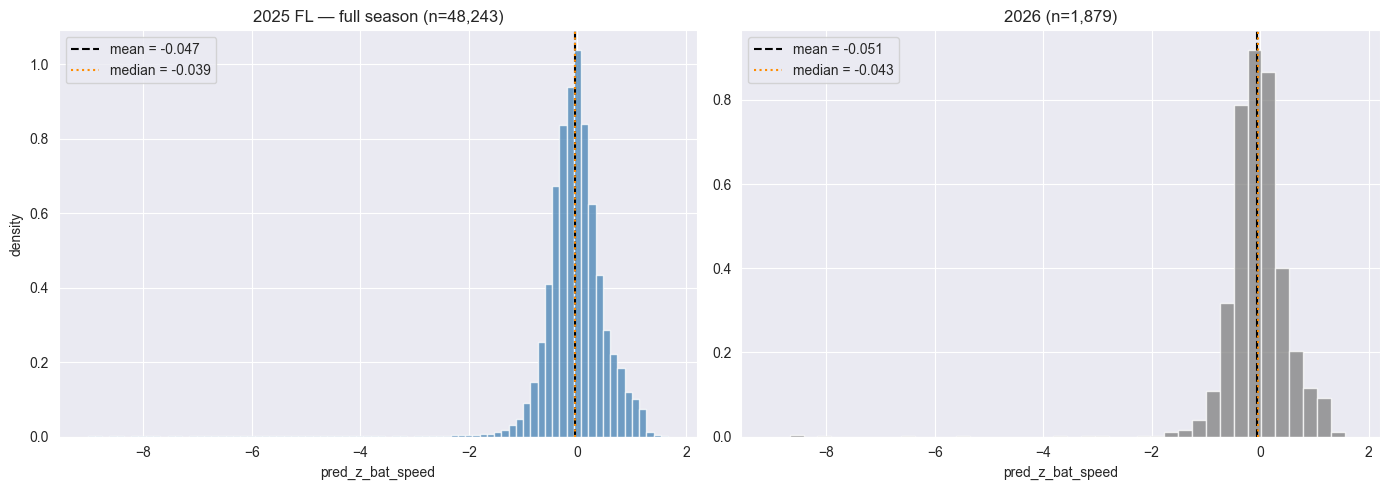

2025 FL distribution:
count    48243.000
mean        -0.047
std          0.606
min         -9.029
25%         -0.314
50%         -0.039
75%          0.236
max          1.674

2026 ST distribution:
count    1879.000
mean       -0.051
std         0.619
min        -8.674
25%        -0.316
50%        -0.043
75%         0.220
max         1.559


In [27]:
import matplotlib.pyplot as plt

preds_2025 = df[df['year'] == 2025]['pred_z_bat_speed'].dropna()
preds_2026 = df[df['year'] == 2026]['pred_z_bat_speed'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=False)

# 2025 — the real distribution
axes[0].hist(preds_2025, bins=80, color='steelblue', alpha=0.75, density=True)
axes[0].axvline(preds_2025.mean(), color='black', linestyle='--',
                label=f'mean = {preds_2025.mean():.3f}')
axes[0].axvline(preds_2025.median(), color='darkorange', linestyle=':',
                label=f'median = {preds_2025.median():.3f}')
axes[0].set_title(f'2025 FL — full season (n={len(preds_2025):,})')
axes[0].set_xlabel('pred_z_bat_speed')
axes[0].set_ylabel('density')
axes[0].legend()

# 2026 — small sample, for comparison
axes[1].hist(preds_2026, bins=40, color='gray', alpha=0.75, density=True)
axes[1].axvline(preds_2026.mean(), color='black', linestyle='--',
                label=f'mean = {preds_2026.mean():.3f}')
axes[1].axvline(preds_2026.median(), color='darkorange', linestyle=':',
                label=f'median = {preds_2026.median():.3f}')
axes[1].set_title(f'2026 (n={len(preds_2026):,})')
axes[1].set_xlabel('pred_z_bat_speed')
axes[1].legend()

plt.tight_layout()
plt.show()

# Summary stats
print('2025 FL distribution:')
print(preds_2025.describe().round(3).to_string())
print('\n2026 ST distribution:')
print(preds_2026.describe().round(3).to_string())

In [28]:
# Check 1: are inputs on the right scale?
print("Sample of X being fed to model.predict:")
sample = df[BAT_SPEED_FEATURES].head(5)
print(sample)
print("\nIf these look like raw exit velos (~80-100), launch angles (~-20 to 50), etc.,")
print("then z-scoring is missing.")

# Check 2: are the spikes tied to specific feature values?
print("\nMost common predictions:")
print(df['pred_z_bat_speed'].round(2).value_counts().head(10))

# Check 3: feature distribution within each spike
df['pred_bucket'] = pd.cut(df['pred_z_bat_speed'],
                           bins=[-1, 0.4, 0.85, 1.5, 2.0],
                           labels=['low_spike', 'mid_spike', 'main_mode', 'high_tail'])
print("\nFeature means within each prediction cluster:")
print(df.groupby('pred_bucket')[BAT_SPEED_FEATURES].mean().round(2))

Sample of X being fed to model.predict:
   launch_speed  height_inches  launch_angle  spray_angle  is_2_strikes
0      65.16129           73.0     78.618341    13.873563             0
1      94.42045           72.0     26.321234    18.107089             0
2      74.07730           72.0     50.869161   -78.817315             1
3      99.11004           71.0      1.833650   -30.408675             0
4      63.48096           72.0    -32.432043    13.395381             1

If these look like raw exit velos (~80-100), launch angles (~-20 to 50), etc.,
then z-scoring is missing.

Most common predictions:
pred_z_bat_speed
-0.01    572
-0.04    548
-0.02    539
-0.05    534
 0.00    532
-0.03    525
 0.02    520
 0.04    516
 0.01    514
 0.05    508
Name: count, dtype: int64

Feature means within each prediction cluster:
             launch_speed  height_inches  launch_angle  spray_angle  \
pred_bucket                                                           
low_spike           77.14        

C:\Users\215nt\AppData\Local\Temp\ipykernel_35180\2940244937.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('pred_bucket')[BAT_SPEED_FEATURES].mean().round(2))


In [29]:
print("2026 BBE counts per batter (top 30):")
counts_2026 = (df[df['year'] == 2026]
               .groupby([BATTER_COL, BATTER_NAME])
               .size()
               .sort_values(ascending=False))
print(counts_2026.head(30))
print(f"\nTotal 2026 batters: {len(counts_2026)}")
print(f"  with >= 16 BBE: {(counts_2026 >= 16).sum()}")
print(f"  with >= 10 BBE: {(counts_2026 >= 10).sum()}")
print(f"   with >= 5 BBE: {(counts_2026 >= 5).sum()}")
print(f"\nTotal 2026 BBE in df: {len(df[df['year']==2026])}")

2026 BBE counts per batter (top 30):
batter_id   batter             
694463      Booker, Kyle           48
699606      Skinner, Brayland      42
1000027220  Cerny, Victor          41
691468      Craig, Alec            36
695688      Holman, Jack           35
1000050271  Dunlap, James          34
1000121595  Edwards, Kyle          34
1000429130  Crowl, Kyle            34
657538      Castro, Ruben          33
693508      Furr, Kasten           33
702125      Calarco, Anthony       33
1000052425  Fitzgerald, Kyle       32
1000026167  Holt, Travis           32
1000429109  McArthur, Liam         32
672858      Mateo, Edwin           32
1000109970  Brown, Graham          31
828612      Hacopian, Eddie        31
668993      Farmer, Justin         31
824666      Liquori, Jeff          31
682204      Brown, Logan           31
839315      Fowler, Cole           31
10029185    Shaneyfelt, Tyler      30
1000067100  Fedko, Christian       30
1000029311  Ruiz, Daryl            29
554054      Gonzale